# 阶段 2 · 第 2 课：把计数表换成神经网络

上一课用**数数**做出了 bigram 模型：loss 2.45，能编名字。可它有个死穴：想多看几个字母，表就爆炸（27⁴ ≈ 53 万格，大部分是 0）。

这一课换一条路：不数了，让一个**神经网络**自己学出那张表。用的是阶段 1 学过的那一套：前向算 loss → 反向求梯度 → 沿负梯度走一小步。

**终点预告**：这一课结束时，你会看到训练过程打印出：

```
第   0 步  loss 3.7590
第  20 步  loss 2.5728
...
第 199 步  loss 2.4624
```

loss 从 3.76 一路降到 2.46，几乎追上数数的 2.45。用同一个随机种子编名字，编出来的和上一课**几乎一模一样**：

```
cexze
momasurailezityha
konimittain
```

两条完全不同的路，走到了同一个地方。第 7 步你会弄明白为什么。

最后，你会亲手调一个大模型 API 里天天见的参数：**temperature**（温度）。调低，1000 个名字只编出 182 种，调到 0 时永远只编出一个「a」；调高，全是 zoglkurkicazktyhnevozimjttainrlkfak 这种乱码。

一共 8 小步：

| 小步 | 上一步留下的麻烦 | 这一步的办法 | 你填的 TODO |
|---|---|---|---|
| 0 | — | 把上一课的成果搬过来，当「标准答案」 | 无 |
| 1 | 神经网络不吃表格，要吃一道道「题」 | 把数据拆成 (输入, 正确答案) 两列 | TODO 1 |
| 2 | 字母编号不能直接当数用（m = 13 不比 e = 5「大」） | one-hot 编码 | 无 |
| 3 | 有了输入，还没有网络 | 一层 27 个神经元：`xenc @ W` | 无 |
| 4 | 网络输出有正有负，不是概率 | 先 exp 再归一化（softmax） | TODO 2 |
| 5 | 有了概率，还不知道好不好 | 挑出正确答案的概率，算 loss（一行，不用循环） | TODO 3 |
| 6 | W 是随机的，loss 很高 | 梯度下降：PyTorch 自动求梯度 | TODO 4 |
| 7 | 训完了，学到的是什么？ | 和数数的结果逐格对照，再编名字 | 无 |
| 8 | 只能照着概率抽，没法调「稳一点」还是「放飞一点」 | 温度：先把 logits 除以 T 再 softmax | TODO 5 |

**怎么上**：`names.txt` 和这个笔记本放在同一个文件夹。从上往下 `Shift+Enter`，带 `TODO` 的格子先填好再运行。灰色的「▶ 提示」点开才显示，卡住了一级一级点开。

## 第 0 步 · 把上一课的成果搬过来

**这一步要做的**：把第 1 课的数据、编号、计数表 `N`、平滑后的概率表 `P` 重新算一遍。全是上一课你写过的代码，直接运行。

`P` 是这一课的**标准答案**：最后要拿网络学出来的东西和它比。

In [24]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import torch

plt.rcParams["font.sans-serif"] = ["Arial Unicode MS"]  # 让图里能显示中文

words = Path("names.txt").read_text().splitlines()
itos = ["."] + sorted(set("".join(words)))
stoi = {s: i for i, s in enumerate(itos)}


def bigrams(w):
    chs = ["."] + list(w) + ["."]
    return list(zip(chs, chs[1:]))


N = torch.zeros((27, 27), dtype=torch.int32)
for w in words:
    for a, b in bigrams(w):
        N[stoi[a], stoi[b]] += 1

P = (N + 1).float()
P /= P.sum(1, keepdim=True)

print("名字个数:", len(words))
print("a 后面跟 n 的概率（数出来的）:", round(P[stoi["a"], stoi["n"]].item(), 4))

名字个数: 32033
a 后面跟 n 的概率（数出来的）: 0.1604


### 先看 N：每一种相邻字符，实际出现了多少次？

先运行上面第 0 步，再运行下面两张图。画图代码直接运行即可，重点是学会读表。

- **纵轴（行）是当前字符，横轴（列）是下一个字符**。沿着一行看，就是问「这个字符后面跟过谁？」
- 格子里的整数是 `N[i, j]`，颜色越深，出现次数越多；`0` 表示数据里一次也没出现过。
- `.` 在行里表示名字开始，在列里表示名字结束。例如 `. → a` 是以 a 开头，`a → .` 是以 a 结尾。
- 橙框标出 `a → n`，方便和下一张概率图对照。两张图的色条单位不同，不要直接跨图比较颜色深浅。

画图用的 `imshow` 把矩阵画成色块，`text` 在格子里写数，`colorbar` 标出颜色对应的数值。


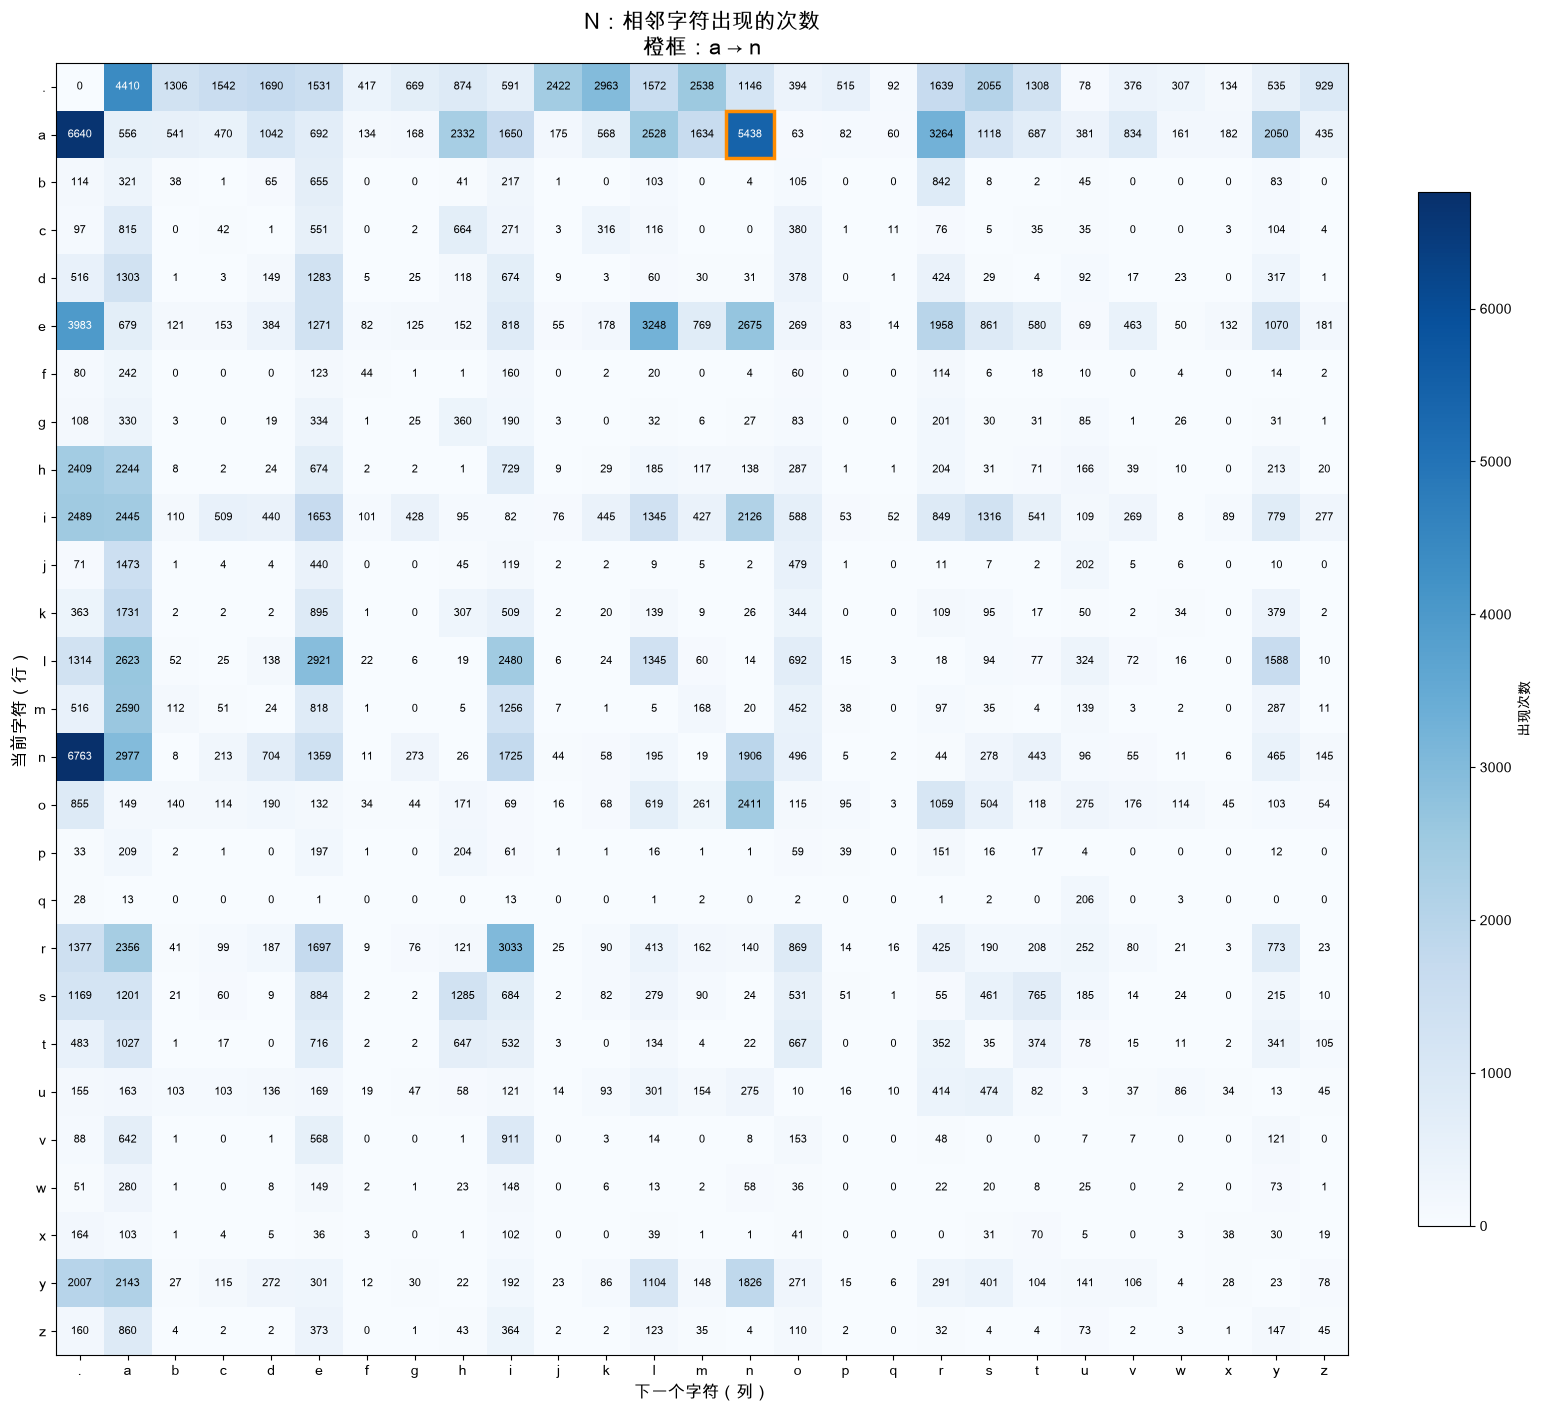

a → n 出现了 5,438 次。
a 这一行合计 33,885 次；这是所有 a → 下一个字符的次数。


In [25]:
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(16, 14), layout="constrained")
heatmap = ax.imshow(N, cmap="Blues", vmin=0)  # 直接画原始次数，线性色阶
ax.set_xticks(range(len(itos)), itos)
ax.set_yticks(range(len(itos)), itos)
ax.set_xlabel("下一个字符（列）", fontsize=12)
ax.set_ylabel("当前字符（行）", fontsize=12)
ax.set_title("N：相邻字符出现的次数\n橙框：a → n", fontsize=16)
fig.colorbar(heatmap, ax=ax, shrink=0.8, label="出现次数")

for row in range(len(itos)):
    for col in range(len(itos)):
        value = N[row, col].item()
        ax.text(col, row, str(value), ha="center", va="center", fontsize=8,
                color="white" if value > N.max().item() * 0.55 else "black")

ax.add_patch(Rectangle((stoi["n"] - 0.5, stoi["a"] - 0.5), 1, 1,
                       fill=False, edgecolor="darkorange", linewidth=2.5))
plt.show()

print(f"a → n 出现了 {N[stoi['a'], stoi['n']].item():,} 次。")
print(f"a 这一行合计 {N[stoi['a']].sum().item():,} 次；这是所有 a → 下一个字符的次数。")


### 再看 P：已知当前字符，下一个字符各有多大概率？

行、列的位置与 N 完全一样，但格子里的数现在是**百分比**。例如 `16.04` 表示约 16.04%。

本课先给 N 的每一格加 1，再除以**各自那一行**的总和：

$$P[i,j] = \frac{N[i,j]+1}{\sum_k N[i,k]+27}$$

分母加 27，是因为一行有 27 个格子，每格都加了 1。

- **每行的真实概率相加都是 1（100%）**；显示值经过四舍五入，相加可能略有偏差。
- 原来次数为 0 的格子，现在也有很小的正概率。这就是 **+1 平滑**，不代表它在数据里真的出现过。
- 图中 `<0.01` 表示小于 0.01%，不是 0；右侧色条也以百分比为单位。

`PercentFormatter(1.0)` 只把色条上的 0～1 显示成 0%～100%，不会修改 P。


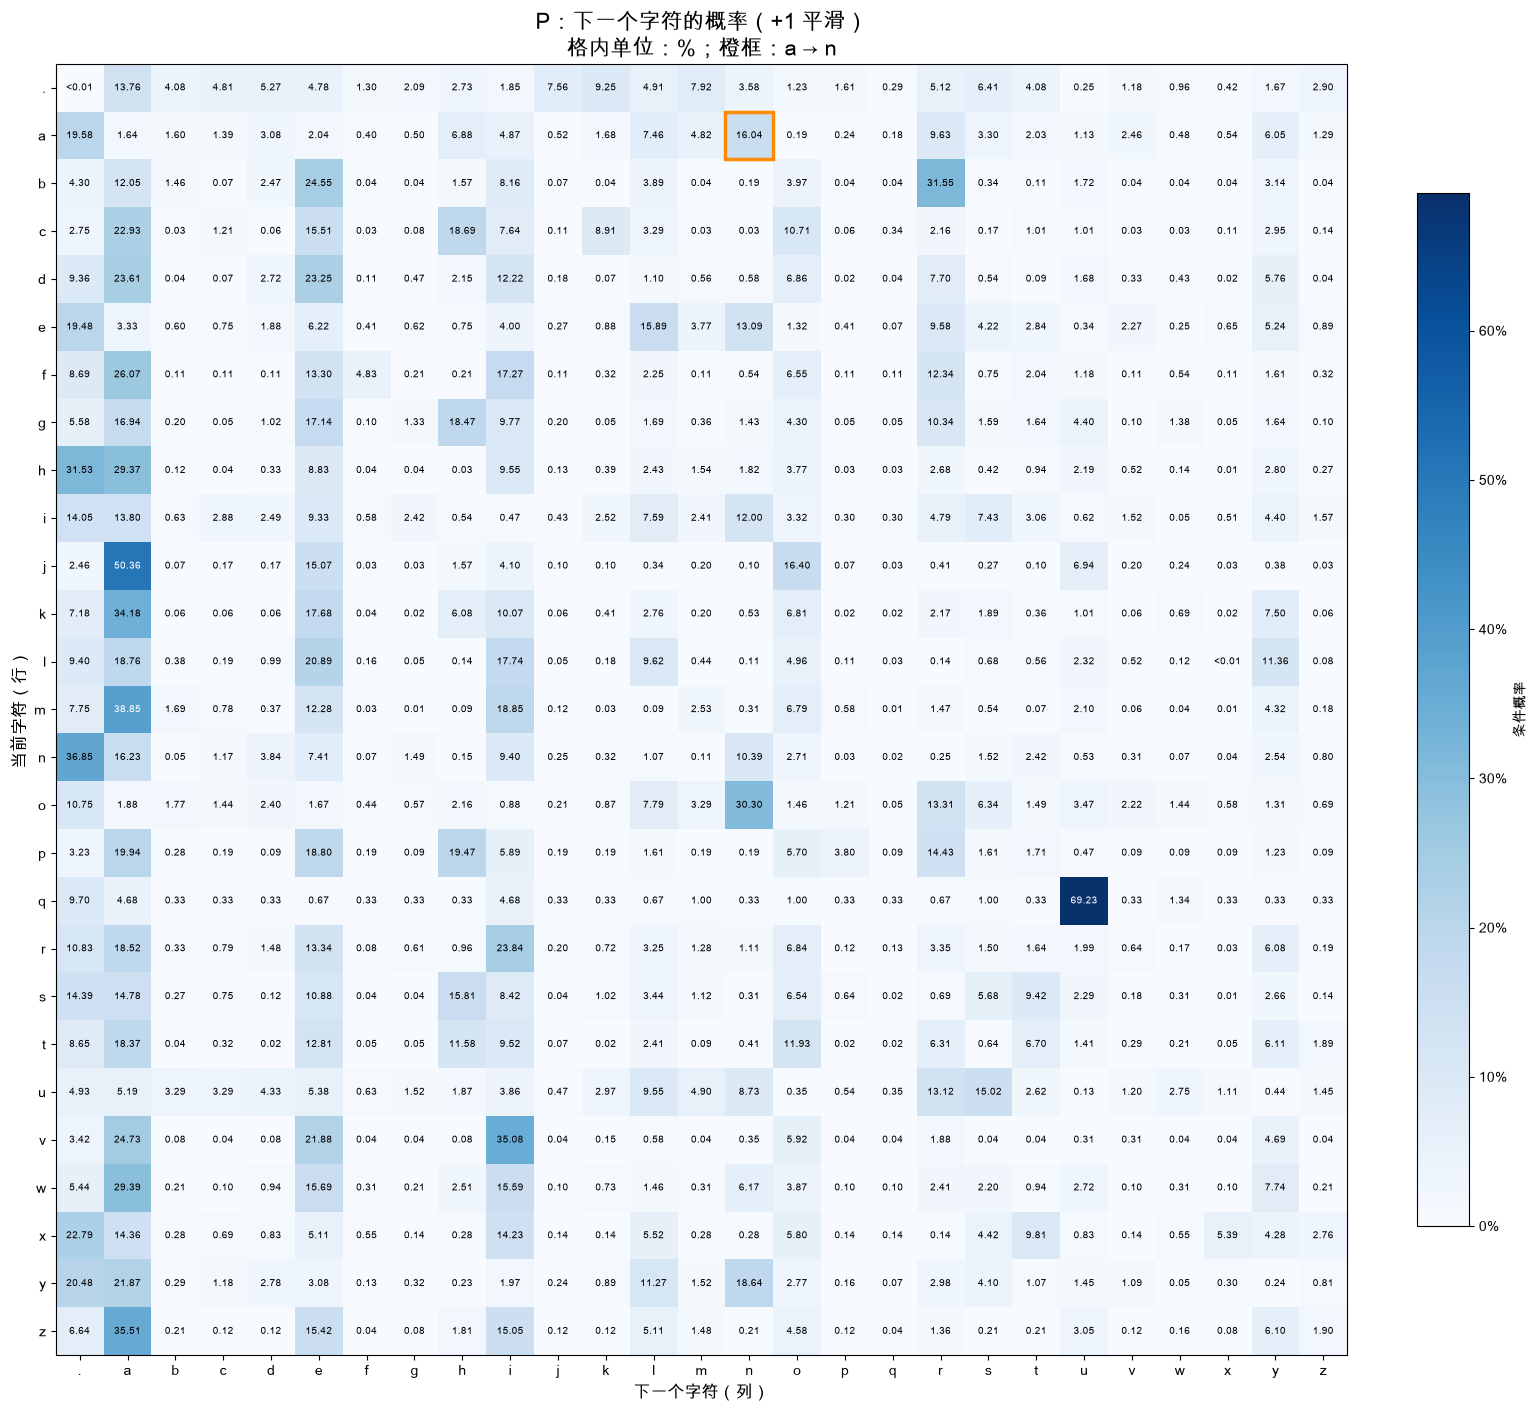

a → n：(5438 + 1) / (33885 + 27) = 16.04%
a 行的概率总和：1.000000
所有行的概率和都约等于 1： True


In [26]:
from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(16, 14), layout="constrained")
heatmap = ax.imshow(P, cmap="Blues", vmin=0)  # 直接画概率，线性色阶
ax.set_xticks(range(len(itos)), itos)
ax.set_yticks(range(len(itos)), itos)
ax.set_xlabel("下一个字符（列）", fontsize=12)
ax.set_ylabel("当前字符（行）", fontsize=12)
ax.set_title("P：下一个字符的概率（+1 平滑）\n格内单位：%；橙框：a → n", fontsize=16)
fig.colorbar(heatmap, ax=ax, shrink=0.8, label="条件概率",
             format=PercentFormatter(1.0))

for row in range(len(itos)):
    for col in range(len(itos)):
        value = P[row, col].item()
        label = "<0.01" if 0 < value < 0.0001 else f"{value * 100:.2f}"
        ax.text(col, row, label, ha="center", va="center", fontsize=7.5,
                color="white" if value > P.max().item() * 0.55 else "black")

ax.add_patch(Rectangle((stoi["n"] - 0.5, stoi["a"] - 0.5), 1, 1,
                       fill=False, edgecolor="darkorange", linewidth=2.5))
plt.show()

count_an = N[stoi["a"], stoi["n"]].item()
total_a = N[stoi["a"]].sum().item()
print(f"a → n：({count_an} + 1) / ({total_a} + 27) = {P[stoi['a'], stoi['n']].item():.2%}")
print(f"a 行的概率总和：{P[stoi['a']].sum().item():.6f}")
print("所有行的概率和都约等于 1：", torch.allclose(P.sum(1), torch.ones(len(itos))))


### 对照两张图，先想这三个问题

1. N 的 `a → n` 比 `q → u` 大，是否说明「a 后面跟 n」的概率也更高？去 P 里找这两个格子。
2. N 的 `. → .` 是 0，为什么 P 的同一格却不是 0？采样时如果从 `.` 直接抽到 `.`，会生成什么？
3. P 是每一行相加等于 1，还是整张表相加等于 1？为什么？

<details><summary>对照解释</summary>

1. 不一定。N 记录实际次数，a 本身出现得多；P 要除以各自那一行的总数，比较的是「已知前一个字符」时的概率。q 虽然少见，但它后面跟 u 的比例很高。
2. +1 平滑给这一格也加了 1，所以概率大于 0。从开始标记直接抽到结束标记，会生成空名字。
3. **每行**等于 1。一行固定了一个当前字符，列举它后面所有可能的结果；整张表有 27 个这样的分布，总和约为 27。

</details>

先记住：**N 回答「出现过多少次」；P 回答「已知当前字符，下一个字符各有多大可能」**。这里的 P 来自计数；第 7 步的 `P_net` 才是神经网络学出的概率表。


应该是 0.1604。

**还剩的麻烦**：`N` 是一张表。神经网络没法直接「吃」一张表，它要的是一道一道的题：给一个输入，告诉它正确答案是什么。

## 第 1 步 · 把数据拆成一道道题

**上一步留下的麻烦**：数据是一张计数表，神经网络要的是 (输入, 正确答案) 这样的题。

**这一步的办法**：每个 bigram 就是一道题。emma 拆成 5 道：

| 题号 | 输入（前一个字母） | 正确答案（下一个字母） |
|---|---|---|
| 1 | . | e |
| 2 | e | m |
| 3 | m | m |
| 4 | m | a |
| 5 | a | . |

把所有输入放进列表 `xs`，所有正确答案放进 `ys`，都用编号存（`stoi` 换）。

**要用到的写法**：
- `列表.append(x)`：在列表末尾加一个元素
- `torch.tensor(列表)`：把 Python 列表变成张量。后面要做矩阵运算，必须是张量（新写法）

```python
torch.tensor([0, 5, 13])   # → tensor([ 0,  5, 13])
```

<details><summary>提示</summary>

和上一课 TODO 2 几乎一样：上一课是 `N[stoi[a], stoi[b]] += 1`，这次不加到表里，而是分别 append 到两个列表。

</details>

<details><summary>答案</summary>

```python
xs.append(stoi[a])
ys.append(stoi[b])
```

</details>

In [27]:
xs, ys = [], []
for w in words:
    for a, b in bigrams(w):
        # TODO 1：把 a 的编号加进 xs，把 b 的编号加进 ys
        xs.append(stoi[a])
        ys.append(stoi[b])

assert len(xs) == 228146, "先完成 TODO 1：一共应该有 228146 道题"
xs = torch.tensor(xs)  # ← 新：列表 → 张量
ys = torch.tensor(ys)
n = xs.nelement()  # 题目总数

print("一共", n, "道题")
print("前 5 道题的输入:", xs[:5])
print("前 5 道题的答案:", ys[:5])

一共 228146 道题
前 5 道题的输入: tensor([ 0,  5, 13, 13,  1])
前 5 道题的答案: tensor([ 5, 13, 13,  1,  0])


前 5 道正好是 emma：输入 `[0, 5, 13, 13, 1]`（. e m m a），答案 `[5, 13, 13, 1, 0]`（e m m a .）。

**还剩的麻烦**：输入是编号，比如 m 是 13、e 是 5。可神经网络会拿输入去**乘**权重，m 就会被当成 e 的 2.6 倍，这毫无道理：字母之间没有大小关系。

## 第 2 步 · one-hot：编号变成一排开关

**上一步留下的麻烦**：编号不能直接当数用。

**这一步的办法**：把每个编号变成一排 27 个数，只有自己那一位是 1，其他全是 0。像 27 个开关，只开一个。这叫 **one-hot 编码**。

| 字母 | 编号 | one-hot（27 个数） |
|---|---|---|
| . | 0 | 1 0 0 0 0 0 … 0 |
| a | 1 | 0 1 0 0 0 0 … 0 |
| e | 5 | 0 0 0 0 0 1 … 0 |

这样所有字母「平等」：谁也不比谁大，只是开的位置不同。

**要用到的 API**：
- `import torch.nn.functional as F`：PyTorch 里一堆现成函数，习惯简写成 `F`（新写法，只是 import）
- `F.one_hot(编号张量, num_classes=27)`：一次把所有编号变成 one-hot，结果是整数
- `.float()`：变成小数，后面才能和小数权重相乘

直接运行：

形状: torch.Size([228146, 27])
前 5 行（emma 的 5 个输入）:
tensor([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.]])


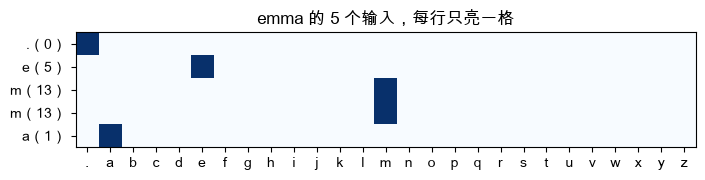

In [28]:
import torch.nn.functional as F  # ← 新

xenc = F.one_hot(xs, num_classes=27).float()
print("形状:", xenc.shape)
print("前 5 行（emma 的 5 个输入）:")
print(xenc[:5])

plt.figure(figsize=(8, 2))
plt.imshow(xenc[:5], cmap="Blues")
plt.yticks(range(5), [f"{itos[i]}（{i}）" for i in xs[:5].tolist()])
plt.xticks(range(27), itos)
plt.title("emma 的 5 个输入，每行只亮一格")
plt.show()

形状是 `(228146, 27)`：22 万多道题，每道题一行 27 个数。

**想一想**：`xenc` 占多少内存？（每个 float32 是 4 字节）

<details><summary>答案</summary>

228146 × 27 × 4 ≈ 2464 万字节 ≈ 24.6 MB。几乎全是 0，有点浪费，第 7 步会看到其实有更省的写法。

</details>

**还剩的麻烦**：输入准备好了，网络还没有。

## 第 3 步 · 一层 27 个神经元

**上一步留下的麻烦**：有输入，没网络。

**这一步的办法**：做一层神经元。阶段 1 的神经元算的是 `w1·x1 + w2·x2 + … + b`。现在：

- 输入有 27 个数（one-hot），所以每个神经元有 27 个权重（这里先不要 b）
- 输出要给 27 个字母各打一个分，所以要 27 个神经元

27 个神经元 × 27 个权重 = 一个 27×27 的矩阵 `W`。所有题一起算，就是一次矩阵乘法 `xenc @ W`（阶段 0 学过 `@`）：

```
xenc      @   W        =   logits
(228146, 27)  (27, 27)     (228146, 27)
```

每道题得到 27 个分数，叫 **logits**。`W` 先随机初始化，用固定的种子，保证你我结果一样。

直接运行：

In [29]:
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27, 27), generator=g)  # 27 个神经元，每个 27 个权重，随机初始化

logits = xenc @ W
print("logits 的形状:", logits.shape)
print("第 1 道题（输入 .）的 27 个分数:")
print(logits[0])

logits 的形状: torch.Size([228146, 27])
第 1 道题（输入 .）的 27 个分数:
tensor([ 1.5674, -0.2373, -0.0274, -1.1008,  0.2859, -0.0296, -1.5471,  0.6049,
         0.0791,  0.9046, -0.4713,  0.7868, -0.3284, -0.4330,  1.3729,  2.9334,
         1.5618, -1.6261,  0.6772, -0.8404,  0.9849, -0.1484, -1.4795,  0.4483,
        -0.0707,  2.4968,  2.4448])


**想一想**：one-hot 只有一位是 1。`xenc[0] @ W` 实际上算出了什么？先猜，再运行下面这格验证。

其实就是w的第k行。

<details><summary>提示 1</summary>

设 one-hot 只有第 k 位是 1。矩阵乘法里，第 j 个输出 = Σᵢ xᵢ·W[i, j]，除了 i = k，其他项都乘了 0。

</details>

<details><summary>提示 2</summary>

所以第 j 个输出就是 W[k, j]。把 27 个 j 都排起来，是 W 的哪一部分？

</details>

<details><summary>答案</summary>

就是 **W 的第 k 行**。one-hot 乘矩阵 = 按编号**查表取一行**。第 1 道题输入是 `.`（编号 0），所以 `logits[0]` 就是 `W[0]`。

这意味着 W 和上一课的计数表 N 是同一个形状、同一种用法：第 k 行管「k 后面跟什么」。

</details>

In [30]:
print("logits[0]:", logits[0][:6])
print("W[0]     :", W[0][:6])
print("一样吗？", torch.allclose(logits[0], W[xs[0]]))

logits[0]: tensor([ 1.5674, -0.2373, -0.0274, -1.1008,  0.2859, -0.0296])
W[0]     : tensor([ 1.5674, -0.2373, -0.0274, -1.1008,  0.2859, -0.0296])
一样吗？ True


**还剩的麻烦**：logits 有正有负（比如 -1.10），每行加起来也不是 1，不能当概率用。

## 第 4 步 · softmax：分数变概率

**上一步留下的麻烦**：logits 有负数，行和不是 1。

**这一步的办法**分两步：

1. **exp**：对每个数取 e 的幂。eˣ 永远是正数，而且 x 越大 eˣ 越大，排名不变。得到的东西可以看成「次数」，叫 `counts`
2. **归一化**：每一行除以这一行的总和。上一课 TODO 3 做过一模一样的事（记得 `keepdim=True`）

这两步合起来叫 **softmax**，大模型最后一层都是它。

**要用到的写法**：
- `张量.exp()`：每个元素取 eˣ（新写法）

```python
torch.tensor([0.0, 1.0, -1.0]).exp()   # → tensor([1.0000, 2.7183, 0.3679])
```

<details><summary>提示 1</summary>

第一行：`counts = logits.exp()`。

</details>

<details><summary>提示 2</summary>

第二行照抄上一课第 5 步：`F / F.sum(1, keepdim=True)`，把 F 换成 counts。

</details>

<details><summary>答案</summary>

```python
counts = logits.exp()
probs = counts / counts.sum(1, keepdim=True)
```

</details>

In [31]:
# TODO 2：先用 exp 把 logits 变成正数 counts，再让每一行除以这一行的总和，得到 probs
counts = logits.exp()
probs = counts / counts.sum(1, keepdim=True)

assert probs is not None, "先完成 TODO 2"
print("probs 的形状:", probs.shape)
print("第 1 道题的 27 个概率:", probs[0])
print("前 5 行各自加起来:", probs.sum(1)[:5])
assert torch.allclose(probs.sum(1), torch.ones(n)), "每一行加起来应该等于 1"

probs 的形状: torch.Size([228146, 27])
第 1 道题的 27 个概率: tensor([0.0607, 0.0100, 0.0123, 0.0042, 0.0168, 0.0123, 0.0027, 0.0232, 0.0137,
        0.0313, 0.0079, 0.0278, 0.0091, 0.0082, 0.0500, 0.2378, 0.0603, 0.0025,
        0.0249, 0.0055, 0.0339, 0.0109, 0.0029, 0.0198, 0.0118, 0.1537, 0.1459])
前 5 行各自加起来: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000])


**想一想**：为什么用 exp，不直接把负数改成 0？

<details><summary>提示</summary>

如果某个分数被改成 0，它的概率就是 0。上一课 andrejq 遇到 0 概率出了什么事？另外，改成 0 这一步，对分数求导是多少？

</details>

<details><summary>答案</summary>

两个原因：① exp 永远大于 0，不会给出 0 概率，loss 不会变成无穷大；② exp 处处可导而且导数不为 0，梯度能一路传回 W。直接截成 0 的地方，梯度也是 0，W 就学不动了（阶段 1 作业里 relu 在负半边的问题）。

</details>

**还剩的麻烦**：每道题都有了 27 个概率，可还不知道网络猜得好不好。

## 第 5 步 · loss：一行算完 22 万道题

**上一步留下的麻烦**：要给网络打分。

**这一步的办法**：和上一课一样，用平均负对数似然：每道题看网络给**正确答案**的概率是多少，取 log，求平均，取负号。

上一课是用 for 循环一道一道取的。先看看 emma 的 5 道题这样取：

In [39]:
# 我想知道第i个题的答案的概率：probs[i, ys[i]，
# 举个例子：probs[0, 2]    # 第 0 条样本的下一个字符是 b 的概率，一个数
# probs[0]       # 第 0 条样本的全部 27 个预测概率，shape 是 [27]

print(probs[5,ys[5]])
probs[0]

tensor(0.2378)


tensor([0.0607, 0.0100, 0.0123, 0.0042, 0.0168, 0.0123, 0.0027, 0.0232, 0.0137,
        0.0313, 0.0079, 0.0278, 0.0091, 0.0082, 0.0500, 0.2378, 0.0603, 0.0025,
        0.0249, 0.0055, 0.0339, 0.0109, 0.0029, 0.0198, 0.0118, 0.1537, 0.1459])

In [ ]:
for i in range(5):
    print(f"第 {i + 1} 题：输入 {itos[xs[i]]}，答案 {itos[ys[i]]}，网络给答案的概率 {probs[i, ys[i]].item():.4f}")

第 1 题：输入 .，答案 e，网络给答案的概率 0.0123
第 2 题：输入 e，答案 m，网络给答案的概率 0.0181
第 3 题：输入 m，答案 m，网络给答案的概率 0.0267
第 4 题：输入 m，答案 a，网络给答案的概率 0.0737
第 5 题：输入 a，答案 .，网络给答案的概率 0.0150


概率都只有 1%～7%：W 是随机的，网络在瞎猜。

问题是：训练时每走一步都要重算一次 loss，要走几百步。每次都用 Python 循环 22 万次，太慢了。

**要用到的写法**（新写法）：一次取出很多格。两个下标都给一个张量，PyTorch 会一一配对着取：

```python
probs[torch.arange(5), ys[:5]]
# 等于 [probs[0, ys[0]], probs[1, ys[1]], probs[2, ys[2]], probs[3, ys[3]], probs[4, ys[4]]]
```

`torch.arange(5)` 就是 `tensor([0, 1, 2, 3, 4])`：第 0 题、第 1 题……每题取它自己的答案那一格。

In [33]:
print(probs[torch.arange(5), ys[:5]])  # ← 新：一次取 5 格，和上面循环的结果一样

tensor([0.0123, 0.0181, 0.0267, 0.0737, 0.0150])


In [43]:
print(probs[torch.arange(100),ys[:100]])

tensor([0.0123, 0.0181, 0.0267, 0.0737, 0.0150, 0.2378, 0.0526, 0.0135, 0.0367,
        0.1056, 0.1059, 0.0150, 0.0100, 0.0051, 0.0235, 0.0150, 0.0313, 0.1022,
        0.0121, 0.0396, 0.0098, 0.0115, 0.0365, 0.0173, 0.0150, 0.0055, 0.0133,
        0.0299, 0.0373, 0.0166, 0.1059, 0.0150, 0.0042, 0.0921, 0.0201, 0.0899,
        0.0549, 0.0290, 0.0318, 0.0498, 0.0080, 0.0290, 0.0082, 0.0164, 0.1059,
        0.0150, 0.0100, 0.0112, 0.0200, 0.0115, 0.0135, 0.1059, 0.0150, 0.0137,
        0.0201, 0.0899, 0.0292, 0.0199, 0.0916, 0.0339, 0.0123, 0.0501, 0.0048,
        0.0115, 0.0383, 0.0055, 0.1556, 0.0100, 0.0396, 0.0046, 0.0074, 0.0194,
        0.0048, 0.0470, 0.0107, 0.0123, 0.0181, 0.0164, 0.0470, 0.0383, 0.0301,
        0.0123, 0.0115, 0.0135, 0.0114, 0.0270, 0.0396, 0.0098, 0.0486, 0.0067,
        0.0494, 0.0082, 0.0164, 0.0470, 0.0173, 0.0150, 0.0123, 0.0115, 0.0365,
        0.0173])


现在对**全部 n 道题**这样取，算出 loss。

**要用到的写法**：
- `张量.log()`：每个元素取自然对数
- `张量.mean()`：所有元素求平均

<details><summary>提示 1</summary>

先取出全部 n 道题正确答案的概率：`probs[torch.arange(n), ys]`。

</details>

<details><summary>提示 2</summary>

后面接 `.log().mean()`，最前面加负号。

</details>

<details><summary>答案</summary>

```python
loss = -probs[torch.arange(n), ys].log().mean()
```

</details>

In [44]:
t0 = time.perf_counter()
slow = 0.0
for i in range(n):
    slow += -torch.log(probs[i, ys[i]]).item()
slow /= n
t_slow = time.perf_counter() - t0
print(f"循环版：loss = {slow:.4f}，用了 {t_slow:.2f} 秒")

t0 = time.perf_counter()
# TODO 3：用一行算出全部 n 道题的平均负对数似然
loss = -probs[torch.arange(n), ys].log().mean()

assert loss is not None, "先完成 TODO 3"
t_fast = time.perf_counter() - t0
print(f"一行版：loss = {loss.item():.4f}，用了 {t_fast:.4f} 秒，快了 {t_slow / t_fast:.0f} 倍")

循环版：loss = 3.7590，用了 1.06 秒
一行版：loss = 3.7590，用了 0.0330 秒，快了 32 倍


loss 应该是 **3.7590**。

**想一想**：上一课第 2 步的瞎猜模型（27 个字母一样概率），loss 是 log 27 ≈ 3.2958。随机的 W 比瞎猜还**差**，为什么？

<details><summary>提示 1</summary>

看第 3 步打印出的 logits[0]：最大的 1.57，最小的 -1.10。exp 以后差多少倍？

</details>

<details><summary>提示 2</summary>

如果把 W 全设成 0，每行的 27 个 logits 都一样，softmax 以后是什么？

</details>

<details><summary>答案</summary>

随机 W 让网络对某些字母**很自信**，可这些自信是乱来的：猜错时给正确答案的概率比 1/27 还小，log 罚得很重。W 全是 0 时，每个字母概率都是 1/27，loss 正好是 3.2958。所以「不知道」比「瞎自信」好。大模型初始化时故意把最后一层的权重设得很小，就是这个道理。

</details>

**顺便**：这套「softmax + 取正确答案的概率 + 负对数平均」太常用了，PyTorch 有现成的一行，叫**交叉熵**。直接运行，和你的结果对一下：

In [45]:
print("PyTorch 现成的:", F.cross_entropy(logits, ys).item())

PyTorch 现成的: 3.758953332901001


一样。以后可以直接用它；这一课还是自己写，看清楚每一步。

**还剩的麻烦**：W 是随机的，loss 3.76，比瞎猜还差。要把 W 的 729 个数调好。

## 第 6 步 · 训练：梯度下降

**上一步留下的麻烦**：W 不好，要调 729 个数。

**这一步的办法**：阶段 1 那一套，一模一样。不同的是这次不用自己写的 `Value`，PyTorch 的张量自带自动求导：

| 阶段 1 你写的 | PyTorch |
|---|---|
| `Value(2.0)` 自动记录计算图 | 建张量时加 `requires_grad=True`（新写法） |
| `loss.backward()` | `loss.backward()`，一样 |
| `p.grad` | `W.grad`，形状和 W 一样，27×27 |
| `p.data += -lr * p.grad` | `W.data += -lr * W.grad`，一样 |
| 每步先 `p.grad = 0.0` | `W.grad = None`（清空，下次 backward 时从 0 开始算） |

**设备**：这一课用 CPU。我在 M1 Pro 上实测过：走 100 步，CPU 约 1.5 秒，mps 约 3 秒。W 只有 729 个数，运算太小，搬数据、发指令的开销比算本身还大，GPU 反而慢。

**学习率**：这里用 50，比阶段 1 大很多。loss 是 22 万道题的**平均**，每道题只拉动 W 的一行，摊到每个数上的梯度很小，步子就得迈大。下面的提示里有不同学习率的实测对比。

<details><summary>提示 1</summary>

三件事，顺序是：清空梯度 → 反向传播 → 更新。

</details>

<details><summary>提示 2</summary>

清空：`W.grad = None`。反向：`loss.backward()`。更新：沿着**负**梯度走一步，步长 `lr`。

</details>

<details><summary>答案</summary>

```python
W.grad = None
loss.backward()
W.data += -lr * W.grad
```

</details>

In [46]:
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27, 27), generator=g, requires_grad=True)  # ← 新：让 PyTorch 记录计算图
lr = 50

t0 = time.perf_counter()
for k in range(200):
    # 前向：和第 3～5 步一模一样
    logits = xenc @ W
    counts = logits.exp()
    probs = counts / counts.sum(1, keepdim=True)
    loss = -probs[torch.arange(n), ys].log().mean()

    # TODO 4：反向 + 更新，三行
    W.grad = None
    loss.backward()
    W.data += -lr * W.grad

    if k % 20 == 0 or k == 199:
        print(f"第 {k:3d} 步  loss {loss.item():.4f}")

print(f"用了 {time.perf_counter() - t0:.1f} 秒")
assert loss.item() < 2.5, "先完成 TODO 4：200 步以后 loss 应该降到 2.5 以下"

第   0 步  loss 3.7590
第  20 步  loss 2.5728
第  40 步  loss 2.5087
第  60 步  loss 2.4880
第  80 步  loss 2.4783
第 100 步  loss 2.4727
第 120 步  loss 2.4690
第 140 步  loss 2.4666
第 160 步  loss 2.4648
第 180 步  loss 2.4634
第 199 步  loss 2.4624
用了 3.3 秒


最后应该是 **2.4624**。数数的结果是 2.4546，已经很接近了；多训几百步还会更近。

<details><summary>不同学习率的实测（训 200 步）</summary>

| 学习率 | 第 10 步 | 第 50 步 | 第 200 步 |
|---|---|---|---|
| 0.1 | 3.7508 | 3.7154 | 3.5956 |
| 1 | 3.6806 | 3.4085 | 2.9502 |
| 10 | 3.2154 | 2.6994 | 2.5098 |
| 50 | 2.7115 | 2.4971 | 2.4624 |

学习率 0.1 时 200 步几乎没动。

</details>

**还剩的麻烦**：loss 是降下来了，可网络到底学到了什么？W 里的 729 个数是什么意思？

## 第 7 步 · 网络学到了什么

**上一步留下的麻烦**：W 是个黑盒。

**这一步的办法**：和上一课数出来的 `P` 逐格对照。网络的概率表就是把 W 的每一行 softmax 一下（第 3 步说过，one-hot 乘 W = 取 W 的一行）。直接运行：

a 后面跟 n：数出来 0.1604，网络学到 0.1605


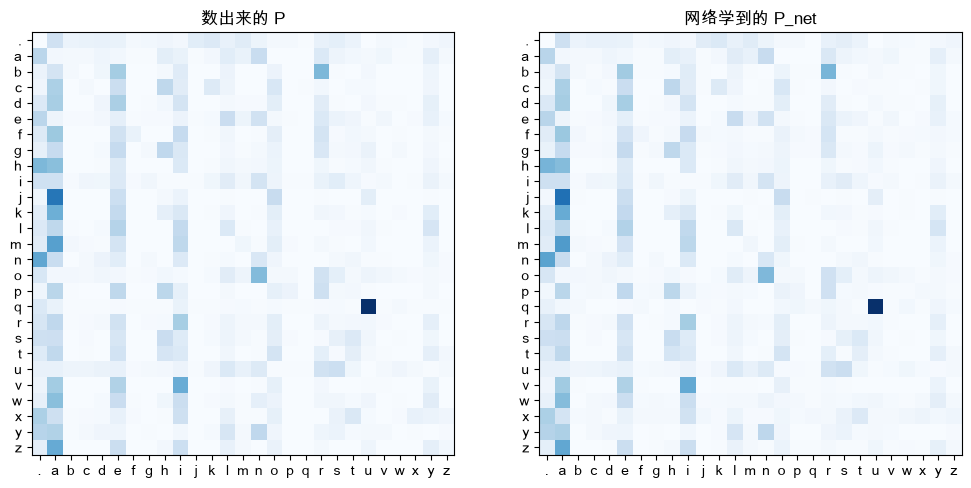

In [48]:
P_net = W.exp()
P_net = P_net / P_net.sum(1, keepdim=True)
P_net = P_net.detach()  # ← 新：只要数，不要计算图了

a, nn_ = stoi["a"], stoi["n"]
print(f"a 后面跟 n：数出来 {P[a, nn_].item():.4f}，网络学到 {P_net[a, nn_].item():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, table, title in [(axes[0], P, "数出来的 P"), (axes[1], P_net, "网络学到的 P_net")]:
    ax.imshow(table, cmap="Blues")
    ax.set_xticks(range(27), itos)
    ax.set_yticks(range(27), itos)
    ax.set_title(title)
plt.show()

两张图几乎看不出区别。

**想一想**：网络从没「数」过，为什么会学出和数数一样的表？下面这格打印 `W` 的 a 那一行减去 `log(N + 1)` 的 a 那一行，先猜会是什么样，再运行：

In [49]:
print((W[a] - torch.log((N[a] + 1).float())).detach())

tensor([-6.5607, -6.5628, -6.5628, -6.5632, -6.5617, -6.5623, -6.5697, -6.5687,
        -6.5611, -6.5613, -6.5682, -6.5627, -6.5610, -6.5613, -6.5608, -6.5370,
        -6.5592, -6.5442, -6.5609, -6.5616, -6.5623, -6.5638, -6.5620, -6.5689,
        -6.5679, -6.5612, -6.5634])


<details><summary>提示 1</summary>

27 个数几乎一样，都在 -6.57 左右。如果 W[a] = log(计数) + 常数，exp 以后是什么？

</details>

<details><summary>提示 2</summary>

exp(log(计数) + c) = 计数 × eᶜ。每一格都乘同一个 eᶜ，再除以行和，eᶜ 会怎样？

</details>

<details><summary>答案</summary>

网络学到的 W 就是 **log(次数)**（每行差一个常数，归一化时消掉了）。所以 logits 可以理解成「对数次数」，exp 以后就是次数，除以行和就是概率：和上一课一步步对上了。

原因：上一课数出来的 P 恰好是让 loss 最小的那张表。网络用梯度下降去找 loss 最小的 W，找到的自然就是同一张表。两条路，同一个终点。

</details>

差得最多的是罕见字母的行，比如 q：

In [50]:
q, u = stoi["q"], stoi["u"]
print(f"q 后面跟 u：数出来 {P[q, u].item():.4f}，网络学到 {P_net[q, u].item():.4f}")
print("q 在输入里出现了", N[q].sum().item(), "次，占全部题目的", f"{N[q].sum().item() / n:.2%}")

q 后面跟 u：数出来 0.6923，网络学到 0.6720
q 在输入里出现了 272 次，占全部题目的 0.12%


<details><summary>提示</summary>

W 的 q 那一行，只有输入是 q 的题才会给它梯度。loss 是全部题目的平均。

</details>

<details><summary>答案</summary>

q 那一行的梯度只来自 272 道题，再除以总数 22 万，非常小，每步只挪一点点。我实测过：训到第 100 步时，网络给 q → u 的概率才 0.373，第 200 步才追到 0.672；而 a 那一行有 3 万多道题在拉，100 步时就和数出来的一样了。**常见的模式学得快，罕见的学得慢**，大模型也一样：数据里少见的知识，要训很久才学会。

</details>

最后用同一个种子编名字。采样代码和上一课一样，只是概率从 `P_net` 来。直接运行：

In [51]:
g = torch.Generator().manual_seed(2147483647)
for _ in range(5):
    out = []
    ix = 0
    while True:
        ix = torch.multinomial(P_net[ix], num_samples=1, replacement=True, generator=g).item()
        if ix == 0:
            break
        out.append(itos[ix])
    print("".join(out))

cexze
momasurailezityha
konimittain
llayn
ka


上一课编出的是 `cexze`、`momasurailezitynn`、`konimittain`、`llayn`、`ka`。几乎一样：只有第二个名字的结尾不同，因为两张表有一点点差别，抽到的字母就岔开了。

这里直接用了 `P_net[ix]` 取一行，没有做 one-hot 再乘 W：第 3 步已经知道这两种是一回事。大模型里也是这样，输入那一层直接「按编号查表取一行」，不真的做 one-hot 乘法，省下 24.6 MB 的 0。这一层有个名字，叫 **embedding**（嵌入），阶段 4 的 Transformer 第一层就是它。

**还剩的麻烦**：编出来的名字有的像样（llayn、ka），有的很离谱（staiyaubrtthrigotai）。模型只有这一张概率表，现在只能照着它抽：想让它稳一点、少出怪名字，或者放飞一点、多编点新花样，都没地方调。

## 第 8 步 · 温度：API 里天天调的那个参数

**上一步留下的麻烦**：只能照着概率表抽，没法调「稳一点」还是「放飞一点」。

**这一步的办法**：做 softmax 之前，先把 logits 除以一个数 T，这个数叫**温度**（temperature）：

```
概率 = softmax(logits / T)
```

几乎所有大模型 API 都有这个参数。调用的时候大概长这样（OpenAI 兼容格式，各家大同小异）：

```python
client.chat.completions.create(
    model="...",
    messages=[{"role": "user", "content": "给我的猫起个名字"}],
    temperature=0.3,
)
```

服务器收到 0.3 以后，每生成一个 token，都做这一课的事：logits 除以 T → softmax → 抽一个。

**想一想**（先猜，再往下做）：T 很小（比如 0.1）时，概率会变成什么样？T 很大（比如 100）呢？

<details><summary>提示 1</summary>

拿三个 logits `[2, 1, 0]` 试：T = 0.5 时变成 `[4, 2, 0]`，差距变大还是变小？T = 10 时变成 `[0.2, 0.1, 0]` 呢？

</details>

<details><summary>提示 2</summary>

exp 会把差距变成倍数：logits 差 1，次数差 e ≈ 2.7 倍；差 2，就差 7.4 倍；差 0.1，只差 1.1 倍。

</details>

<details><summary>答案</summary>

T < 1 把差距拉大，强的更强。T 越小，概率越集中到最大的那一个；T 趋近 0 时就只剩它，每次都抽同一个。

T > 1 把差距压小，T 越大越接近均匀分布（每个 1/27），就是上一课第 2 步的瞎猜。

T = 1 什么都不改，就是模型学到的原样。

</details>

写一个带温度的 softmax。

**要用到的写法**：全都学过。这次 logits 只有一行（27 个数，一维），求和直接用 `.sum()`，不需要 `keepdim`。

`L = W.detach()` 是训练好的 W（只要数，不要计算图）。第 3 步说过，`L[ix]` 就是字母 ix 后面那 27 个字母的 logits。

<details><summary>提示</summary>

三步：`logits / T`，再 `.exp()`，再除以它自己的 `.sum()`。

</details>

<details><summary>答案</summary>

```python
counts = (logits / T).exp()
return counts / counts.sum()
```

</details>

T = 0.3：a 后面直接结束 0.580，跟 n 0.298，最不可能的字母 0.0000
T = 1：a 后面直接结束 0.196，跟 n 0.160，最不可能的字母 0.0018
T = 3：a 后面直接结束 0.076，跟 n 0.071，最不可能的字母 0.0159


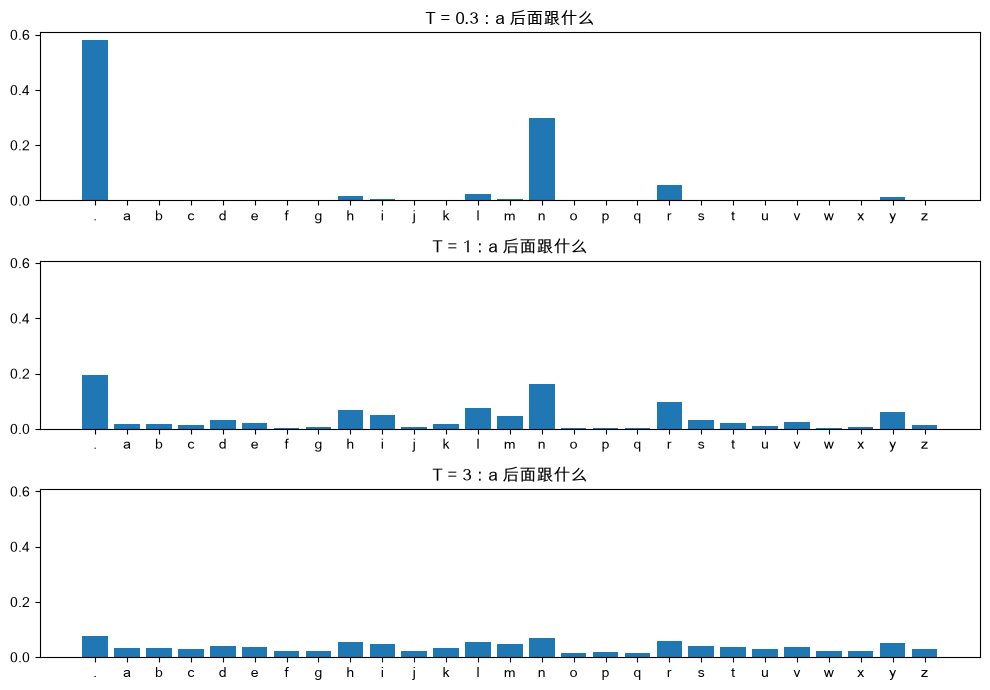

In [52]:
L = W.detach()
a = stoi["a"]


def softmax_T(logits, T):
    # TODO 5：先把 logits 除以温度 T，再 exp，再除以总和，返回 27 个概率
    counts = (logits / T).exp()
    return counts / counts.sum()


assert softmax_T(L[a], 1.0) is not None, "先完成 TODO 5"
assert torch.allclose(softmax_T(L[a], 1.0), P_net[a]), "T = 1 时应该和第 7 步的 P_net 一模一样"

for T in [0.3, 1, 3]:
    p = softmax_T(L[a], T)
    print(f"T = {T}：a 后面直接结束 {p[0].item():.3f}，跟 n {p[stoi['n']].item():.3f}，最不可能的字母 {p.min().item():.4f}")

fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharey=True)
for ax, T in zip(axes, [0.3, 1, 3]):
    ax.bar(range(27), softmax_T(L[a], T))
    ax.set_xticks(range(27), itos)
    ax.set_title(f"T = {T}：a 后面跟什么")
plt.tight_layout()
plt.show()

应该看到：

- T = 0.3：a 后面 58% 直接结束，30% 跟 n，两个加起来快九成，其余字母几乎是 0
- T = 1：和第 7 步的表一样（19.6% 和 16.0%）
- T = 3：最高的才 7.6%，最低的也有 1.6%，几乎拉平了（完全均匀是 1/27 ≈ 3.7%）

用不同温度编名字。采样代码和第 7 步一样，只是概率换成 `softmax_T(L[ix], T)`。直接运行：

In [ ]:
def sample(T, k=10):
    g = torch.Generator().manual_seed(2147483647)
    names = []
    for _ in range(k):
        out = []
        ix = 0
        while True:
            p = softmax_T(L[ix], T)
            ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
            if ix == 0:
                break
            out.append(itos[ix])
        names.append("".join(out))
    return names


for T in [0.3, 1, 3]:
    print(f"T = {T}：", "  ".join(sample(T)))

- T = 0.3：`de bra jali a a a kay a kan ma`，又短又保守，10 个里有 4 个是 a
- T = 1：和第 7 步编的一模一样（cexze、momasurailezityha……），因为 T = 1 什么都没改
- T = 3：`zoglkurkicazktyhnevozimjttainrlkfak` 这种，几乎是乱码

（三组用的是同一串随机数，所以有几个名字长得像，比如 cexze 和 cexzm。）

**想一想**：T = 0 会怎样？`logits / 0` 能算吗？API 里明明可以填 `temperature=0`，那时候服务器在做什么？

<details><summary>提示</summary>

回到上面的答案：T 越小，概率越集中到最大的那一个。T 趋近 0 的极限是什么？

</details>

<details><summary>答案</summary>

除以 0 算不了。实际的做法是：T = 0 时不抽了，**每一步直接选概率最大的那个**，叫**贪心解码**。比如推理框架 vLLM 的文档就写着 temperature 为 0 表示贪心采样。下面这格就是贪心。

</details>

In [18]:
out = []
ix = 0
while True:
    ix = L[ix].argmax().item()  # ← 新：不抽了，直接取 logits 最大的那个编号
    if ix == 0:
        break
    out.append(itos[ix])
print("T = 0（贪心）编出的名字:", "".join(out))

T = 0（贪心）编出的名字: a


只有一个字母：**a**，而且不管运行多少次都是 a。开头最常见的是 a（13.8%），a 后面最常见的是结束（19.6%），每一步都挑最可能的，合起来却是最没意思的名字。

换 1000 个名字，看温度怎么改变整体的样子。直接运行：

In [19]:
word_set = set(words)  # 查「在不在」用集合，比列表快得多
for T in [0.3, 0.5, 1, 2, 3]:
    names = sample(T, k=1000)
    real = sum(nm in word_set for nm in names)
    avg_len = sum(len(nm) for nm in names) / len(names)
    print(f"T = {T:<3}  不重样的 {len(set(names)):4d} 个   数据里真有的 {real / 10:4.1f}%   平均长度 {avg_len:4.1f}")

NameError: name 'sample' is not defined

| T | 不重样的 | 数据里真有的 | 平均长度 |
|---|---|---|---|
| 0.3 | 182 | 38.6% | 2.1 |
| 0.5 | 479 | 34.0% | 3.2 |
| 1 | 821 | 9.9% | 6.3 |
| 2 | 927 | 3.1% | 11.2 |
| 3 | 947 | 1.4% | 14.3 |

温度低：稳，常见，但老在重复；温度高：新花样多，但越来越不像名字。这是一个取舍，没有哪个温度绝对好。

**想一想**：温度能让模型变得更准吗？下面这格用不同温度算整个数据集的 loss，先猜哪个 T 最小，再运行：

In [20]:
for T in [0.3, 0.5, 1, 2, 3]:
    loss_T = F.cross_entropy(xenc @ L / T, ys).item()
    print(f"T = {T:<3}  loss {loss_T:.4f}")

T = 0.3  loss 3.6654
T = 0.5  loss 2.7787
T = 1    loss 2.4623
T = 2    loss 2.6404
T = 3    loss 2.7975


<details><summary>答案</summary>

T = 1 最小（2.4623，比第 6 步打印的 2.4624 小一点点，因为第 6 步打印的是最后一次更新之前的 loss），往两边都变大。

温度不会增加模型的知识。T = 1 就是模型学到的分布本身，调温度只是换一种抽法：要稳就调低，要新就调高。

</details>

**这在真实产品里长什么样**：DeepSeek 的 API 文档（2026 年 10 月查）建议按场景设 temperature，默认是 1.0：

| 场景 | 建议的 temperature |
|---|---|
| 代码生成 / 数学解题 | 0.0 |
| 数据抽取 / 分析 | 1.0 |
| 通用对话 | 1.3 |
| 翻译 | 1.3 |
| 创意类写作 / 诗歌创作 | 1.5 |

**想一想**：为什么代码和数学建议 0，写诗建议 1.5？用上面 1000 个名字的那张表来解释。

<details><summary>答案</summary>

代码、数学通常只有一个对的答案，要的是「最可能」的那条路，不要惊喜，所以用贪心。写诗要的是新鲜、不重样，宁可偶尔怪一点，所以调高。就像编名字：T = 0.3 时 1000 个名字只有 182 种，T = 3 时几乎都不重样，可多半不像名字。

</details>

**一个坑，给客户讲方案时用得上**：同一个 temperature 数值，在不同厂商那里效果可能不一样。DeepSeek-V3-0324（2025 年 3 月）的模型说明里写过，它的 API 会先把你填的 temperature 换算一下，再用到模型上：

| 你在 API 里填的 | 模型实际用的 |
|---|---|
| 0 到 1 之间 | 乘以 0.3（填 1.0，实际是 0.3） |
| 1 到 2 之间 | 减去 0.7（填 1.5，实际是 0.8） |

原因是很多人调 API 时不改默认值 1.0，而这个模型在 0.3 左右效果最好。所以上面表里的 1.3、1.5，并不是直接拿 logits 除以 1.3。不同厂商、甚至同一厂商的不同模型，刻度都可能不一样，要以各家文档为准。

API 里和 temperature 一起出现的，常常还有 `top_p`：只在概率最高、加起来到 p 的那几个里面抽，长尾的怪字母直接砍掉。阶段 8 再细讲。

## 跑完想一想

- 把第 6 步的步数从 200 改成 1000，loss 能追上数数的 2.4546 吗？能超过吗？（提示：上一课不加平滑时是 2.4541，那是什么意思？）
- **布道练习**：假设一个开发者问你「temperature 到底调什么」，用这一课编名字的实验，30 秒讲清楚：调低、调高各会怎样，什么场景用多少。写下来或者录一段。

## 还剩的麻烦：阶段 2 到这里收尾

这一课的网络只看 1 个字母，所以最多追平数数。上一课说过要「让它看更多字母」：路线调整以后，这一步不单独做一课了，放到阶段 4 的 Transformer 里一起讲。思路先记一下：

| | 看前 3 个字母 |
|---|---|
| 数数 | 27⁴ ≈ 53 万格的表，大部分是 0 |
| 神经网络 | 每个字母先查表变成几个数（embedding），拼起来再过几层神经元。参数只有几千个，相似的字母还能共用规律 |

还有一个更基本的问题：这两课一直拿**一个字母**当一个单位。真正的大模型每次猜的是一个 **token**，它可能是一个字、半个词，也可能是一整个词。一句中文是几个 token？API 为什么按 token 收费，同样的意思，中文和英文为什么价钱不一样？下一阶段「分词」回答这些。

## 这和大模型有什么关系

| 这一课 | 大模型 / API |
|---|---|
| one-hot @ W = 按编号取一行 | 第一层 embedding，一模一样 |
| logits → softmax → 概率 | 最后一层，一模一样；API 的 `logprobs` 参数返回的就是这些概率取 log |
| logits 除以 T | API 的 `temperature`；填 0 是贪心解码，每次都选最可能的 |
| 照概率抽 | 同一个问题问两次，回答不一样 |
| 平均负对数似然 | 交叉熵 loss（`F.cross_entropy`）；困惑度（perplexity）= e^loss，这一课 e^2.46 ≈ 11.7，相当于每次在 11.7 个字母里犹豫，瞎猜是 27 |
| `W.grad = None`、`backward`、更新 | `optimizer.zero_grad()`、`backward`、`optimizer.step()` |
| 上一课的 +1 平滑 | 训练时的 weight decay（权重衰减）：把参数往 0 拉，意思相近 |
| 随机 W 比瞎猜还差 | 初始化时把输出层的权重设小 |
| 罕见的行学得慢 | 罕见的知识要训很久 |

## 本课新词

| 词 | 意思 |
|---|---|
| 训练集 | 一道道 (输入, 正确答案) 的题 |
| one-hot | 只有一位是 1 的一排数，让编号之间没有大小 |
| logits | 网络输出的原始分数，可正可负；可以理解成「对数次数」 |
| softmax | 先 exp 再归一化，把分数变成概率 |
| 交叉熵 | softmax 后取正确答案的概率，负对数平均；就是上一课的 NLL |
| 困惑度 | e^loss，平均每次在几个选项里犹豫 |
| embedding | 按编号查表取一行；one-hot 乘矩阵的省事写法 |
| 温度 | 做 softmax 前 logits 除以的数；低了稳，高了野 |
| 贪心解码 | 每一步都直接选概率最大的，等于温度 0 |

阶段 2 到这里结束。学完告诉我，我来出阶段 2 的作业，会多一些「给别人讲清楚」的题。

## 后续路线更新（2026-10-30）

用户已完成本课，后续转向 **Agent 与业务流程自动化**。下一课是 [课程 3 · 从一句需求到工单草稿](../03-llm-api/lesson.ipynb)，直接接入 API、JSON、字段检查与用量统计。分词和 Transformer 改为按需补课；本文此前提到的后续阶段编号以[新版路线图](../README.md)为准。
